# Прогнозирование продаж: модели временных рядов

ДЗ 2 по курсу «Прогнозирование временных рядов и обработка сигналов». Продолжаем ДЗ 1: товар `85099B` (JUMBO BAG RED RETROSPOT) из датасета [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), продажи в штуках.

План:
1. Подготовить дневной, недельный и месячный ряды и разделить их по времени.
2. Построить модели: наивную и сезонную наивную, ETS, ARIMA, VAR и LightGBM.
3. Выбрать метрики.
4. Сделать прогнозы на горизонтах 1, 7, 31, 61 (день), 1, 4, 8 (неделя), 1, 2 (месяц) и посчитать метрики.
5. Построить графики.
6. Сделать выводы.

Код лежит в `ts_forecast.py`, здесь только вызовы и разбор результатов. Ноутбук выполняется около 3 минут, дольше всего обучается LightGBM.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ts_forecast as tf

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})

## Шаг 1. Подготовка данных

Очистка такая же, как в ДЗ 1: убираем отменённые счета, возвраты и строки с нулевой ценой.

In [2]:
xlsx = tf.download_dataset("data/raw")
raw = tf.load_transactions(xlsx)
clean = tf.clean_transactions(raw)
calendar = tf.trading_calendar(clean)
print(f"строк: {len(raw):,} -> {len(clean):,} после очистки ({1 - len(clean) / len(raw):.1%} удалено)")
print(f"рабочих дней: {len(calendar)}, с {calendar.min().date()} по {calendar.max().date()}")

строк: 541,909 -> 530,104 после очистки (2.2% удалено)
рабочих дней: 305, с 2010-12-01 по 2011-12-09


Из ДЗ 1 берём очистку, календарь работы магазина и выводы анализа. Магазин закрыт по субботам и в праздники, поэтому в неделе 6 рабочих дней (Вс-Пт). Шум мультипликативный, большие пики - это оптовые заказы, ряд тренд-стационарен.

Предобработку из ДЗ 1 для прогноза не используем, потому что она смотрит в будущее: пропуски заполнялись по соседним неделям с обеих сторон и интерполяцией, фильтр Хампеля работал с центрированным окном, тренд оценивался по всему ряду. Поэтому модели получают исходный ряд:
- праздники остаются пропусками;
- если модель не умеет работать с пропусками (ETS, VAR), пропуск заполняется значением того же дня неделю назад, то есть только прошлым;
- log(1 + x) применяется к каждой точке отдельно и ничего не оценивает по данным, поэтому утечки не даёт;
- выбросы не удаляем, оптовые заказы тоже часть спроса.

### Ряды трёх частот

Дневной ряд - сетка Вс-Пт с 04.01 по 08.12.2011, как в ДЗ 1. Один шаг равен одному рабочему дню, поэтому 7 шагов - это неделя и один день, 31 шаг - около 5 недель, 61 шаг - около 10 недель.

Недельный (Вс-Сб) и месячный ряды - суммы дневных продаж. Берём только полные периоды. Данные заканчиваются 09.12 в 12:50, поэтому последняя неделя и декабрь 2011 неполные и отброшены. Декабрь 2010 полный, его в месячный ряд добавляем.

Для LightGBM и VAR нужны ещё ряды:
- панель товаров, которые продавались хотя бы в 80% рабочих дней января-мая 2011, на ней обучается LightGBM;
- сумма продаж других сумок JUMBO BAG, которые регулярно продавались в те же месяцы, это второй ряд для VAR.

Отбираем товары только по январю-маю, потому что эти месяцы входят в начальную обучающую часть всех трёх рядов и в тест не заглядывают.

In [3]:
codes = tf.select_panel(clean, calendar)
peers = tf.jumbo_peers(clean, calendar)
daily = tf.daily_matrix(clean, calendar, codes)
peers_daily = tf.daily_matrix(clean, calendar, peers.index).sum(axis=1, min_count=1)
sets = tf.build_series_sets(daily, peers_daily)
print(f"товаров в панели для LightGBM: {len(codes)} (вместе с целевым)")
print(f"второй ряд для VAR: сумма {len(peers)} товаров")
peers

товаров в панели для LightGBM: 114 (вместе с целевым)
второй ряд для VAR: сумма 10 товаров


,описание,доля дней с продажами
StockCode,,
22386,JUMBO BAG PINK POLKADOT,0.934
21929,JUMBO BAG PINK VINTAGE PAISLEY,0.876
21928,JUMBO BAG SCANDINAVIAN PAISLEY,0.860
20712,JUMBO BAG WOODLAND ANIMALS,0.851
85099F,JUMBO BAG STRAWBERRY,0.793
22385,JUMBO BAG SPACEBOY DESIGN,0.769
20711,JUMBO BAG TOYS,0.744
22663,JUMBO BAG DOLLY GIRL DESIGN,0.653
21033,JUMBO BAG CHARLIE AND LOLA TOYS,0.603


### Проверка индекса

In [4]:
tf.index_report(sets).T

ряд,День,Неделя,Месяц
шаг,"рабочий день, Вс-Пт",неделя Вс-Сб,месяц
начало,2011-01-04,2011-01-08,2010-12-01
конец,2011-12-08,2011-12-03,2011-11-01
N,291,48,12
индекс возрастает,True,True,True
дублей,0,0,0
шаг в днях (мин/макс),1/2,7/7,28/31
NaN (праздники),7,0,0
нулей,4,0,0
начальное обучение,140,24,6


Индекс возрастает, дублей нет. Шаг у дневного ряда 1 день (через субботу 2 дня), у недельного 7 дней, у месячного 28-31.

В дневном ряду 7 пропусков. Это праздники: Пасха, свадьба 29.04, банковские выходные в мае и августе. Они остаются NaN. 4 нуля - рабочие дни, когда этот товар не покупали.

### Обучение и тест

Используем прогноз с расширяющимся окном. Первые `n_init` наблюдений - начальная обучающая часть. Дальше в каждой точке T модель заново обучается на наблюдениях 0..T-1 и прогнозирует позицию T-1+h. Данные не перемешиваются, после T модель ничего не видит.

Оцениваемые даты для всех горизонтов одни и те же: это конец ряда, начиная с позиции `n_init + max(h) - 1`. Например, на 1 сентября горизонт 1 даёт прогноз по данным до 31 августа, а горизонт 61 - по данным примерно на 10 недель раньше. Так разница между горизонтами зависит только от того, насколько старые данные видит модель, а не от того, что оцениваются разные месяцы.

Одно разбиение train/test не подходит: на каждый горизонт пришлась бы одна ошибка, а на месячном ряду это одно число на модель.

В таблице для каждого горизонта видно, до какой даты модель видит данные и какие даты прогнозирует. Начальное обучение заканчивается в мае - середине июня, оцениваемые даты идут с июля-августа по начало декабря.

In [5]:
tf.split_report(sets)

последнее наблюдение (с) последнее наблюдение (по) прогноз на (с) прогноз на (по)  прогнозов  с фактом
ряд    h                                                                                                        
День   1                2011-08-24                2011-12-07     2011-08-25      2011-12-08         91        90
       7                2011-08-17                2011-11-30     2011-08-25      2011-12-08         91        90
       31               2011-07-20                2011-11-02     2011-08-25      2011-12-08         91        90
       61               2011-06-15                2011-09-28     2011-08-25      2011-12-08         91        90
Неделя 1                2011-08-06                2011-11-26     2011-08-13      2011-12-03         17        17
       4                2011-07-16                2011-11-05     2011-08-13      2011-12-03         17        17
       8                2011-06-18                2011-10-08     2011-08-13      2011-12-03         17        17
Месяц  1                2011-06-01                2011-10-01     2011-07-01      2011-11-01          5         5
       2                2011-05-01                2011-09-01     2011-07-01      2011-11-01          5         5

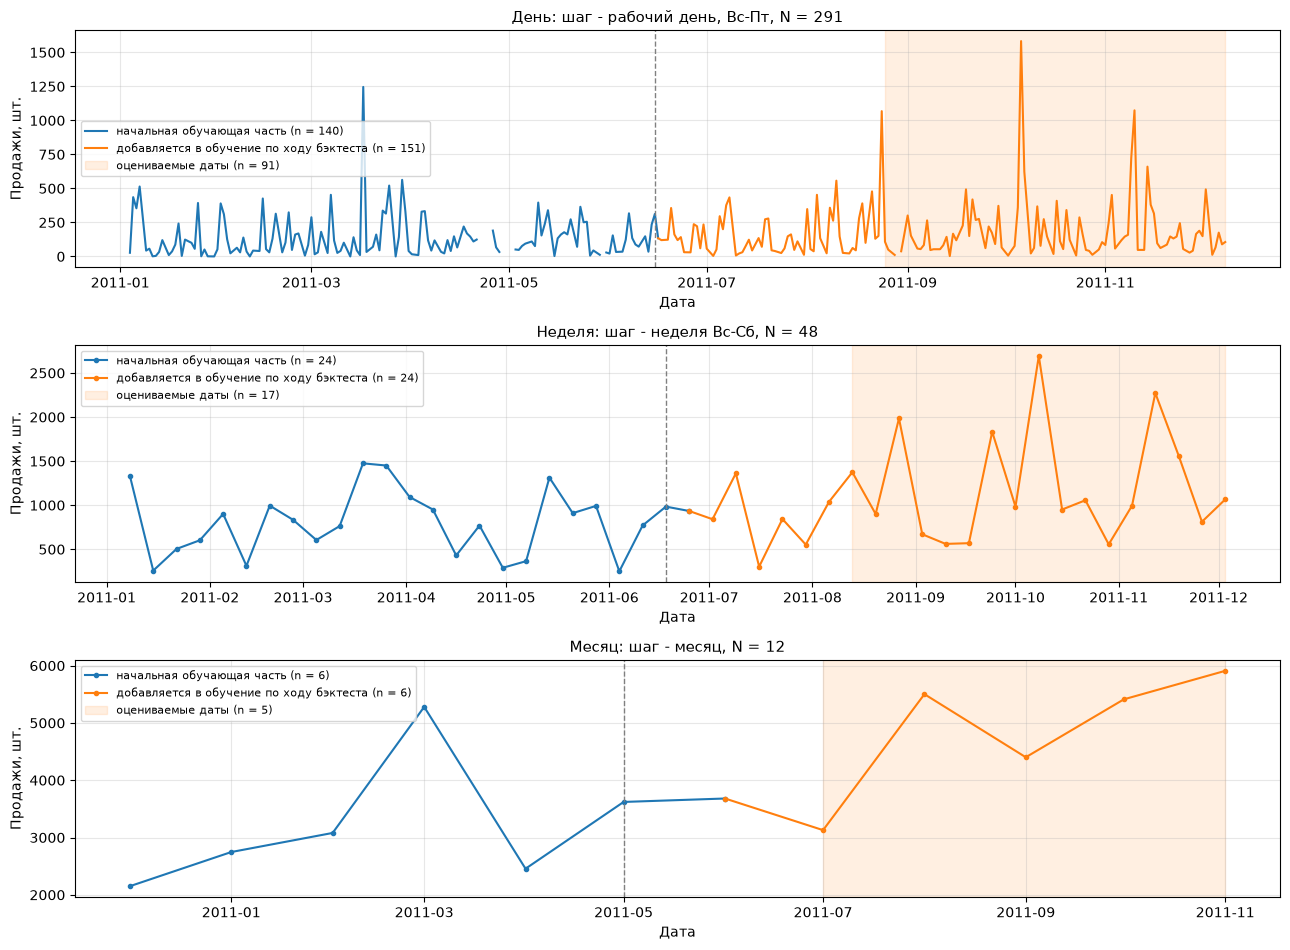

In [6]:
fig = tf.plot_split(sets)
plt.show()

Данные готовы, порядок по времени сохранён. На каждом горизонте оценивается 91 дата у дневного ряда, 17 у недельного и 5 у месячного. Одна дневная дата - банковский выходной 29.08, факта для неё нет, и в метрики она не входит.

На графике видно, что продажи растут с весны, а самые большие значения приходятся на тест, на осень перед Рождеством.

## Шаг 2. Модели

| модель | что делает | частоты |
|---|---|---|
| Наивная | последнее значение | все |
| Сезонная наивная | тот же день недели неделю назад | только день (у недель и месяцев нет полного года) |
| ETS | экспоненциальное сглаживание на log(1 + x), с трендом или без, с недельной сезонностью или без | все |
| ARIMA | SARIMA на log(1 + x), AR(p) входит в перебор как частный случай | все |
| VAR | два ряда: 85099B и другие JUMBO BAG | все |
| LightGBM | бустинг, одна модель на все товары панели, отдельная модель на каждый горизонт | все |

Как выбираются модели:
- Вариант модели (тип ETS, порядок ARIMA, число лагов VAR) выбирается один раз по начальной обучающей части. Дальше в каждой точке переобучаются только параметры. Гиперпараметры LightGBM заданы заранее и на тесте не подбирались.
- ETS, ARIMA, VAR и LightGBM работают с log(1 + x), потому что в ДЗ 1 шум оказался мультипликативным. После обратного преобразования получается медиана прогноза, а не среднее. Для MAE это как раз то, что нужно, но прогноз будет ниже среднего, это видно в столбце «смещение».
- Порядок разности d у ARIMA выбирается тестами ADF и KPSS, а не по AICc: у моделей с разным d правдоподобие считается по разным данным, и AIC сравнивать нельзя. Остальное (p, q, P, Q и тренд) выбирается по AICc.
- У месячного ряда всего 6 точек, тесты на нём ничего не покажут, поэтому там d = 0, как у дневного ряда и в ДЗ 1.
- Пропуски в ARIMA не заполняются, с ними справляется фильтр Калмана.

### Выбор вариантов

In [7]:
models = {f: tf.make_models() for f in sets}
M = {f: {m.name: m for m in models[f]} for f in sets}
for f, s in sets.items():
    for m in models[f]:
        if m.applicable(s):
            m.select(s)

pd.DataFrame([{"частота": f, "модель": m.name, "выбрано": m.describe() or "-"}
              for f, s in sets.items() for m in models[f] if m.applicable(s)]).set_index(["частота", "модель"])

выбрано
частота модель                                                           
День    Наивная                                                         -
        Сезонная наивная                                                -
        ETS                                                    ETS(A,N,A)
        ARIMA                          ARIMA(0, 0, 0)(1,0,1)[6], тренд=ct
        VAR                                              VAR(1), тренд=ct
        LightGBM          LightGBM, своя модель на каждый h, 300 деревьев
Неделя  Наивная                                                         -
        ETS                                                    ETS(A,N,N)
        ARIMA                                     ARIMA(0, 1, 1), тренд=n
        VAR                                               VAR(1), тренд=c
        LightGBM          LightGBM, своя модель на каждый h, 300 деревьев
Месяц   Наивная                                                         -
        ETS                                                    ETS(A,N,N)
        ARIMA                                     ARIMA(0, 0, 0), тренд=c
        VAR                                               VAR(1), тренд=c
        LightGBM          LightGBM, своя модель на каждый h, 300 деревьев

In [8]:
for f in sets:
    print(f"{f}, порядок разности для ARIMA: {M[f]['ARIMA'].d_note}")

rows = []
for f in sets:
    for name in ("ETS", "ARIMA", "VAR"):
        t = M[f][name].table
        crit = "AIC" if name == "VAR" else "AICc"
        for i in range(min(3, len(t))):
            rows.append({"частота": f, "модель": name, "место": i + 1, "вариант": t.loc[i, "модель"],
                         "критерий": crit, "значение": t.loc[i, crit]})
pd.DataFrame(rows).set_index(["частота", "модель", "место"]).round(2)

День, порядок разности для ARIMA: d = 0: ADF p = 0.000, KPSS p (уровень/тренд) = 0.042/0.100
Неделя, порядок разности для ARIMA: d = 1: ADF p = 0.339, KPSS p (уровень/тренд) = 0.100/0.100
Месяц, порядок разности для ARIMA: d = 0: всего 6 точек, тесты не применяем


вариант критерий  значение
частота модель место                                                       
День    ETS    1                              ETS(A,N,A)     AICc   496.920
               2                             ETS(A,Ad,A)     AICc   498.470
               3                              ETS(A,N,N)     AICc   502.010
        ARIMA  1      ARIMA(0, 0, 0)(1,0,1)[6], тренд=ct     AICc   477.830
               2      ARIMA(0, 0, 1)(1,0,1)[6], тренд=ct     AICc   479.350
               3      ARIMA(1, 0, 0)(1,0,1)[6], тренд=ct     AICc   479.420
        VAR    1                        VAR(1), тренд=ct      AIC     0.530
               2                         VAR(1), тренд=c      AIC     0.540
               3                        VAR(6), тренд=ct      AIC     0.540
Неделя  ETS    1                              ETS(A,N,N)     AICc    45.780
               2                             ETS(A,Ad,N)     AICc    55.280
        ARIMA  1                 ARIMA(0, 1, 1), тренд=n     AICc    45.720
               2                 ARIMA(0, 1, 2), тренд=n     AICc    48.330
               3                 ARIMA(1, 1, 1), тренд=n     AICc    48.340
        VAR    1                         VAR(1), тренд=c      AIC    -2.920
               2                        VAR(1), тренд=ct      AIC    -2.760
               3                         VAR(2), тренд=c      AIC    -2.680
Месяц   ETS    1                              ETS(A,N,N)     AICc    20.230
               2                             ETS(A,Ad,N)     AICc       inf
        ARIMA  1                 ARIMA(0, 0, 0), тренд=c     AICc    10.230
               2                 ARIMA(0, 0, 1), тренд=c     AICc    18.910
               3                ARIMA(0, 0, 0), тренд=ct     AICc    19.180
        VAR    1                         VAR(1), тренд=c      AIC    -4.780

Что получилось:
- День: тесты дают d = 0, ряд тренд-стационарный, как и в ДЗ 1. ARIMA выбрала сезонную часть (1,0,1) с периодом 6 и линейный тренд, ETS выбрала недельную сезонность. Недельный цикл из ДЗ 1 модели нашли сами.
- Неделя: ADF не отверг единичный корень (p = 0,34), поэтому d = 1. На 24 точках тест слабый, так что это скорее значит, что стационарность не доказана.
- На неделях и месяцах AICc выбирает самые простые модели: на 24 и 6 точках тренд и лаги не окупаются.

На неделях выбрана ARIMA(0,1,1) без константы. Она эквивалентна простому экспоненциальному сглаживанию ETS(A,N,N) с α = 1 + θ, поэтому прогнозы ETS и ARIMA на неделях почти совпадают. Проверим это на оценённых параметрах.

In [9]:
s = sets["Неделя"]
ets_fit = M["Неделя"]["ETS"].fit_at(s, s.n_init)
arima = M["Неделя"]["ARIMA"]
print("варианты:", M["Неделя"]["ETS"].describe(), "и", arima.describe())
if arima.order == (0, 1, 1) and arima.trend == "n":
    ar_fit = arima.fit_at(s, s.n_init)
    alpha = ets_fit.params[0]
    theta = ar_fit.params[0]
    print(f"ETS: alpha = {alpha:.4f};  ARIMA(0,1,1): theta = {theta:.4f}, 1 + theta = {1 + theta:.4f}")
    print("прогноз на 1 шаг, шт.:", round(float(tf.from_log(ets_fit.forecast(1))[0]), 1),
          "и", round(float(tf.from_log(ar_fit.forecast(1))[0]), 1))

варианты: ETS(A,N,N) и ARIMA(0, 1, 1), тренд=n
ETS: alpha = 0.0001;  ARIMA(0,1,1): theta = -0.9994, 1 + theta = 0.0006
прогноз на 1 шаг, шт.: 700.8 и 700.8


α получилось почти 0: уровень почти не обновляется, и модель прогнозирует среднее за всю историю. В логарифмах начало недельного ряда похоже на шум вокруг постоянного уровня. По той же причине на месяцах ETS(A,N,N) и ARIMA(0,0,0) с константой в большинстве точек дают почти одинаковый прогноз.

### LightGBM

Бустинг на одном ряде из 12 месяцев не обучить: обучающих строк было бы от 4 до 10. Поэтому одна модель обучается сразу на всех товарах панели.
- Признаки считаются в log(1 + x), из них вычитается текущий уровень ряда (среднее за последние несколько шагов). Так товары с разными объёмами продаж становятся сопоставимы.
- Признаки: последние значения (14 для дня, 8 для недели, 3 для месяца), скользящие средние и сам уровень. Для дня добавлены значения того же дня недели, что и у прогнозируемой даты, за 4 последние недели, и номер этого дня недели (он известен заранее).
- На каждый горизонт h обучается своя модель: по признакам в момент t она предсказывает значение в t + h. Свои же прогнозы вместо лагов не подставляются, поэтому ошибки не накапливаются.
- Для точки T модель обучается только на строках с t + h <= T - 1, то есть и признаки, и ответы лежат до T.
- Функция потерь L1, под метрику MAE.

### Проверка на утечку

Строим прогноз из конца начальной обучающей части. Потом строим его ещё раз на копии данных, где все наблюдения после этой точки заменены случайными числами, в том числе в панели товаров и во втором ряде VAR. Если модель где-то смотрит в будущее, прогнозы получатся разными.

In [10]:
tf.leakage_check(models, sets)

макс. разница прогнозов утечка
частота модель                                          
День    Наивная                             0.000    нет
        Сезонная наивная                    0.000    нет
        ETS                                 0.000    нет
        ARIMA                               0.000    нет
        VAR                                 0.000    нет
        LightGBM                            0.000    нет
Неделя  Наивная                             0.000    нет
        ETS                                 0.000    нет
        ARIMA                               0.000    нет
        VAR                                 0.000    нет
        LightGBM                            0.000    нет
Месяц   Наивная                             0.000    нет
        ETS                                 0.000    нет
        ARIMA                               0.000    нет
        VAR                                 0.000    нет
        LightGBM                            0.000    нет

Прогнозы совпали у всех моделей на всех частотах, то есть данные из будущего в модели не попадают.

## Шаг 3. Метрики

| метрика | формула | зачем |
|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert \hat y - y \rvert$ | основная метрика внутри частоты, ошибка в штуках; меньше зависит от редких оптовых пиков, чем RMSE |
| RMSE | $\sqrt{\frac{1}{n}\sum (\hat y - y)^2}$ | показывает, насколько модель промахивается на больших пиках |
| WAPE | $\sum \lvert \hat y - y \rvert / \sum y$ | ошибка в процентах от объёма; не зависит от масштаба, поэтому по ней сравниваем день, неделю и месяц |
| MASE | $\frac{1}{n}\sum \lvert \hat y - y \rvert / s$ | $s$ - MAE наивного прогноза на шаг вперёд на обучающей части; меньше 1 значит точнее наивного прогноза на истории; работает при нулях |
| смещение | $\sum (\hat y - y) / \sum y$ | занижает модель прогноз или завышает |

MAPE и sMAPE не берём. В дневном ряду есть нулевые продажи (4 дня), на них MAPE делится на ноль, а на маленьких значениях сильно раздувается: прогноз 50 при факте 5 даёт ошибку 900%. sMAPE не определена, когда факт и прогноз оба равны нулю.

In [11]:
s = sets["День"]
y_eval = s.y[list(s.targets)]
y_eval = y_eval[np.isfinite(y_eval)]
print(f"оцениваемых дней: {len(y_eval)}; продаж 0 шт.: {(y_eval == 0).sum()}, не больше 10 шт.: {(y_eval <= 10).sum()}")
print(f"медиана {np.median(y_eval):.0f}, среднее {y_eval.mean():.0f}, максимум {y_eval.max():.0f} шт.")

оцениваемых дней: 90; продаж 0 шт.: 0, не больше 10 шт.: 3
медиана 120, среднее 191, максимум 1583 шт.


Среди оцениваемых дней нулей нет, но есть дни с продажами до 10 штук при медиане 120 и максимуме 1583. MAPE на таких данных в основном зависела бы от нескольких дней с маленьким фактом. Из-за такого разброса основной метрикой выбрана MAE, а не RMSE.

## Шаг 4. Прогнозы и оценка

Запускаем бэктест для всех моделей, частот и горизонтов. Каждая строка результата - один прогноз: модель, частота, горизонт, точка прогноза, дата, факт и прогноз. Результаты сохраняются в папку `results`.

In [12]:
t0 = time.time()
bt = pd.concat([tf.backtest(models[f], s, select=False) for f, s in sets.items()], ignore_index=True)
print(f"прогнозов: {len(bt):,}, время: {time.time() - t0:.0f} с")
bt.groupby(["частота", "модель"], sort=False).size().unstack().fillna(0).astype(int)

прогнозов: 2,489, время: 150 с


модель,Наивная,Сезонная наивная,ETS,ARIMA,VAR,LightGBM
частота,,,,,,
День,364,364,364,364,364,364
Неделя,51,0,51,51,51,51
Месяц,10,0,10,10,10,10


In [13]:
table = tf.metrics_table(bt)
Path("results").mkdir(exist_ok=True)
bt.to_csv("results/forecasts.csv", index=False)
table.round(4).to_csv("results/metrics.csv")
table

n       MAE      RMSE  WAPE, %  MASE  смещение, %
частота h  модель                                                              
День    1  LightGBM          90   124.813   236.808   65.362 0.817      -37.461
           ETS               90   126.066   238.829   66.018 0.825      -37.554
           ARIMA             90   126.606   230.391   66.301 0.827      -24.633
           VAR               90   135.321   240.460   70.865 0.884      -31.478
           Наивная           90   186.289   297.417   97.556 1.217        5.598
           Сезонная наивная  90   203.067   320.929  106.342 1.322        8.007
        7  LightGBM          90   125.699   239.798   65.826 0.829      -42.343
           ETS               90   126.680   239.802   66.340 0.836      -38.287
           ARIMA             90   127.181   230.117   66.603 0.837      -23.139
           VAR               90   134.442   240.233   70.405 0.886      -30.605
           Сезонная наивная  90   197.700   327.451  103.532 1.287        8.140
           Наивная           90   213.922   346.318  112.027 1.404        6.057
        31 ETS               90   126.164   242.032   66.070 0.861      -42.605
           LightGBM          90   127.971   247.958   67.016 0.873      -50.761
           ARIMA             90   130.454   227.676   68.317 0.889      -16.706
           VAR               90   134.727   238.229   70.554 0.918      -27.513
           Сезонная наивная  90   185.100   315.539   96.934 1.249       -2.357
           Наивная           90   200.089   325.525  104.783 1.361       -3.654
        61 ETS               90   128.013   246.019   67.038 0.909      -45.635
           LightGBM          90   130.081   251.986   68.121 0.922      -54.951
           VAR               90   139.758   236.659   73.189 0.991      -16.091
           Сезонная наивная  90   151.878   262.670   79.536 1.075      -14.297
           ARIMA             90   154.767   236.570   81.049 1.097       10.311
           Наивная           90   181.500   280.468   95.048 1.283      -14.075
Неделя  1  LightGBM          17   517.853   712.258   42.245 1.137      -24.737
           ETS               17   531.465   761.864   43.356 1.157      -34.601
           ARIMA             17   536.843   768.830   43.794 1.167      -36.926
           VAR               17   554.787   784.894   45.258 1.199      -38.884
           Наивная           17   760.294   931.362   62.023 1.636       -0.130
        4  LightGBM          17   511.179   743.899   41.701 1.156      -35.577
           ARIMA             17   542.029   775.613   44.218 1.210      -38.559
           ETS               17   542.033   775.617   44.218 1.210      -38.560
           VAR               17   549.541   783.920   44.830 1.226      -39.631
           Наивная           17   712.529   928.851   58.127 1.595      -14.276
        8  ARIMA             17   556.506   791.319   45.399 1.360      -40.123
           ETS               17   556.508   791.320   45.399 1.360      -40.123
           VAR               17   563.165   800.583   45.942 1.376      -41.401
           LightGBM          17   589.989   819.909   48.130 1.455      -43.926
           Наивная           17   632.000   846.385   51.557 1.512      -11.574
Месяц   1  LightGBM           5 1,019.134 1,207.956   20.924 0.859      -20.924
           Наивная            5 1,106.800 1,297.472   22.724 0.940       -9.149
           VAR                5 1,266.729 1,517.685   26.008 1.069      -26.008
           ETS                5 1,340.881 1,561.491   27.530 1.127      -27.276
           ARIMA              5 1,539.828 1,778.124   31.615 1.290      -31.361
        2  Наивная            5 1,036.600 1,221.331   21.283 0.860      -16.503
           VAR                5 1,488.291 1,622.381   30.557 1.219      -27.161
           ETS                5 1,630.024 1,860.675   33.467 1.344      -33.467
           ARIMA              5 1,630.033 1,860.686   33.467 1.344      -33.467
           LightGBM           

Это сводная таблица: внутри каждой частоты и горизонта модели отсортированы по MASE, `n` - число дат с фактом.

Ниже для каждой частоты и горизонта лучшая и вторая модели и тест Диболда-Мариано: значимо ли лучшая модель точнее наивной и второй. Тест учитывает, что ошибки прогнозов на h шагов коррелированы между собой. Считаем его, только если дат хотя бы в 3 раза больше горизонта, иначе в таблице NaN.

In [14]:
tf.comparison_table(bt, table)

лучшая модель  MASE  WAPE, %  MAE лучшей / MAE наивной вторая модель  MAE второй / MAE лучшей  p (DM) против наивной  p (DM) против второй
частота h                                                                                                                                            
День    1       LightGBM 0.817   65.362                     0.670           ETS                    1.010                  0.003                 0.616
        7       LightGBM 0.829   65.826                     0.588           ETS                    1.008                  0.005                 0.800
        31           ETS 0.861   66.070                     0.631      LightGBM                    1.014                    NaN                   NaN
        61           ETS 0.909   67.038                     0.705      LightGBM                    1.016                    NaN                   NaN
Неделя  1       LightGBM 1.137   42.245                     0.681           ETS                    1.026                  0.064                 0.714
        4       LightGBM 1.156   41.701                     0.717         ARIMA                    1.060                  0.143                 0.553
        8          ARIMA 1.360   45.399                     0.881           ETS                    1.000                    NaN                   NaN
Месяц   1       LightGBM 0.859   20.924                     0.921       Наивная                    1.086                  0.810                 0.810
        2        Наивная 0.860   21.283                     1.000           VAR                    1.436                    NaN                   NaN

In [15]:
pd.DataFrame({"(медиана - среднее) / среднее, %": {f: tf.median_bias(s) for f, s in sets.items()}}).round(1)

,"(медиана - среднее) / среднее, %"
День,-37.400
Неделя,-18.900
Месяц,11.100


У моделей на log(1 + x) смещение почти везде отрицательное, до -55% (кроме ARIMA на h = 61, про неё в выводах). Главная причина видна в таблице выше: медиана дневных продаж на оцениваемых датах на 37% ниже среднего, потому что распределение сильно скошено оптовыми заказами. Модели прогнозируют медиану. Для MAE и WAPE это лучше, но суммарный объём получается заниженным. Вторая причина - осенний рост, которого не было в обучающей части.

Наивная модель смещена гораздо меньше, но MAE лучших моделей на 30-41% ниже, чем у неё.

## Шаг 5. Визуализация

### Прогноз из одной точки

Прогнозы на максимальный горизонт из конца начальной обучающей части. У LightGBM на каждый горизонт своя модель, поэтому он показан точками только на горизонтах из задания.

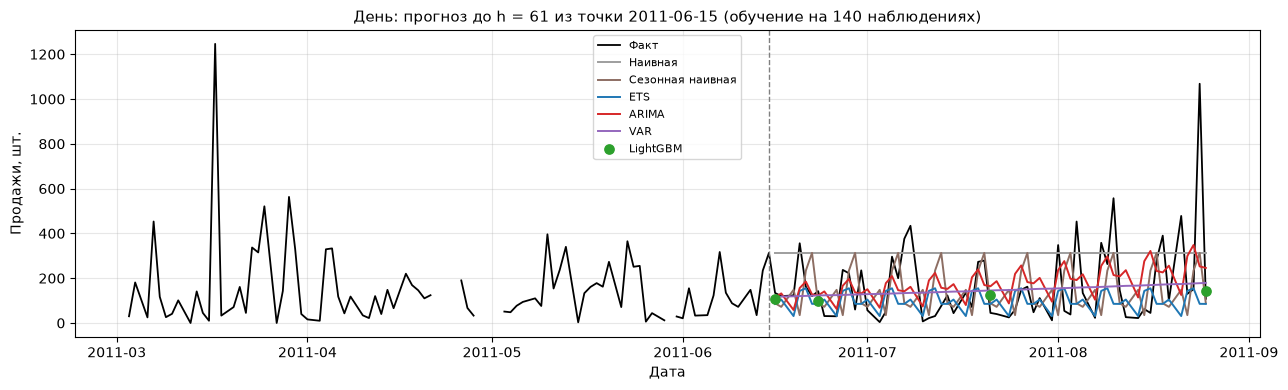

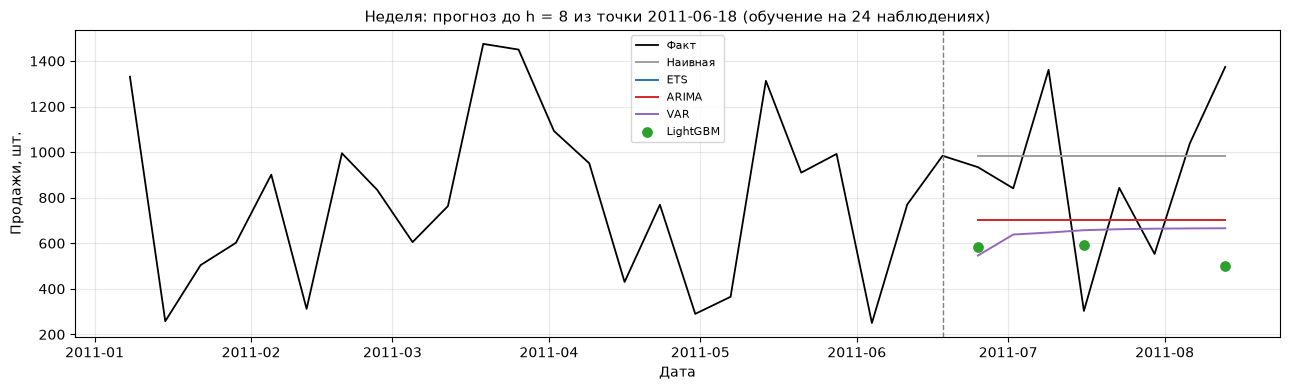

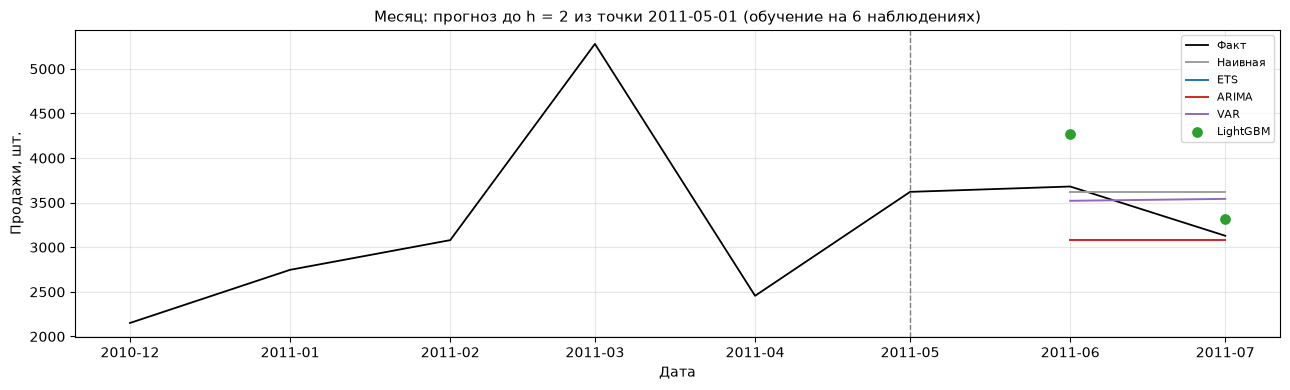

In [16]:
for f, s in sets.items():
    fig = tf.plot_paths(models[f], s, s.n_init, history=90 if f == "День" else 30)
    plt.show()

Модели на log(1 + x) прогнозируют сглаженный уровень около медианы, на дневном ряду с недельным профилем. Наивные модели переносят вперёд последнее значение или последнюю неделю. Отдельные оптовые пики не предсказывает ни одна модель, и это ожидаемо: по прошлым продажам нельзя понять, когда придёт крупный заказ.

На дневном графике ARIMA с линейным трендом к концу горизонта уходит вверх, поэтому на h = 61 её ошибка растёт.

### Прогнозы на каждом горизонте

Для каждого h показаны прогнозы на оцениваемые даты, сделанные за h шагов до них. Чем больше h, тем слабее прогноз реагирует на последние изменения. На дневном графике VAR и наивная модель не показаны, чтобы не загромождать, их метрики есть в таблице.

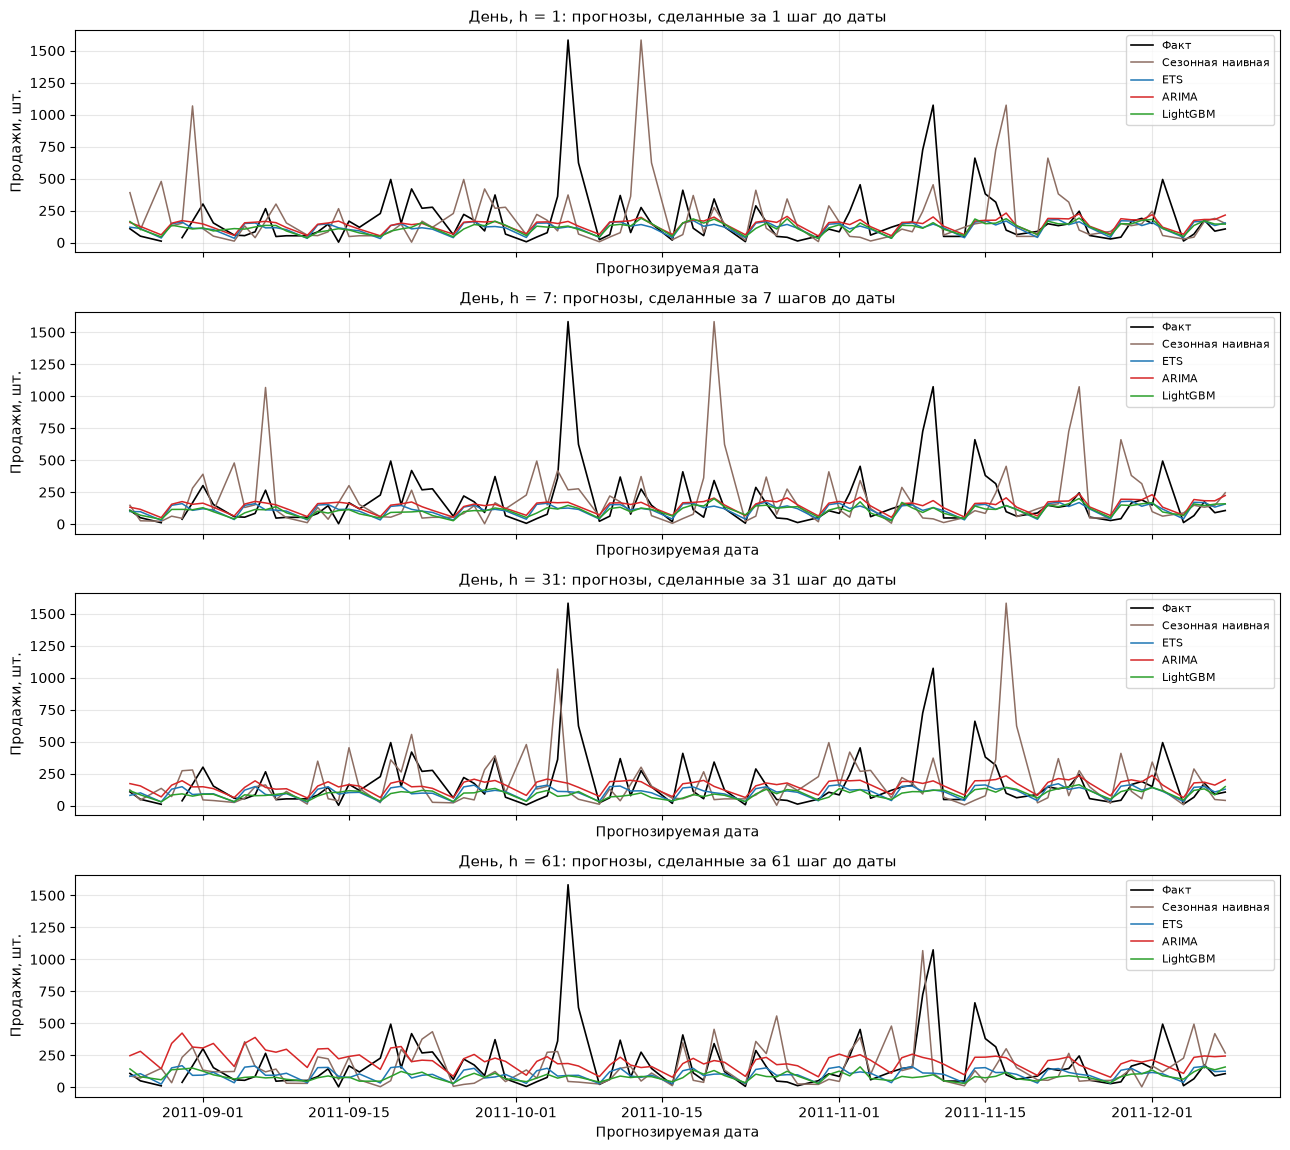

In [17]:
fig = tf.plot_h_step(bt, sets["День"], models=["Сезонная наивная", "ETS", "ARIMA", "LightGBM"])
plt.show()

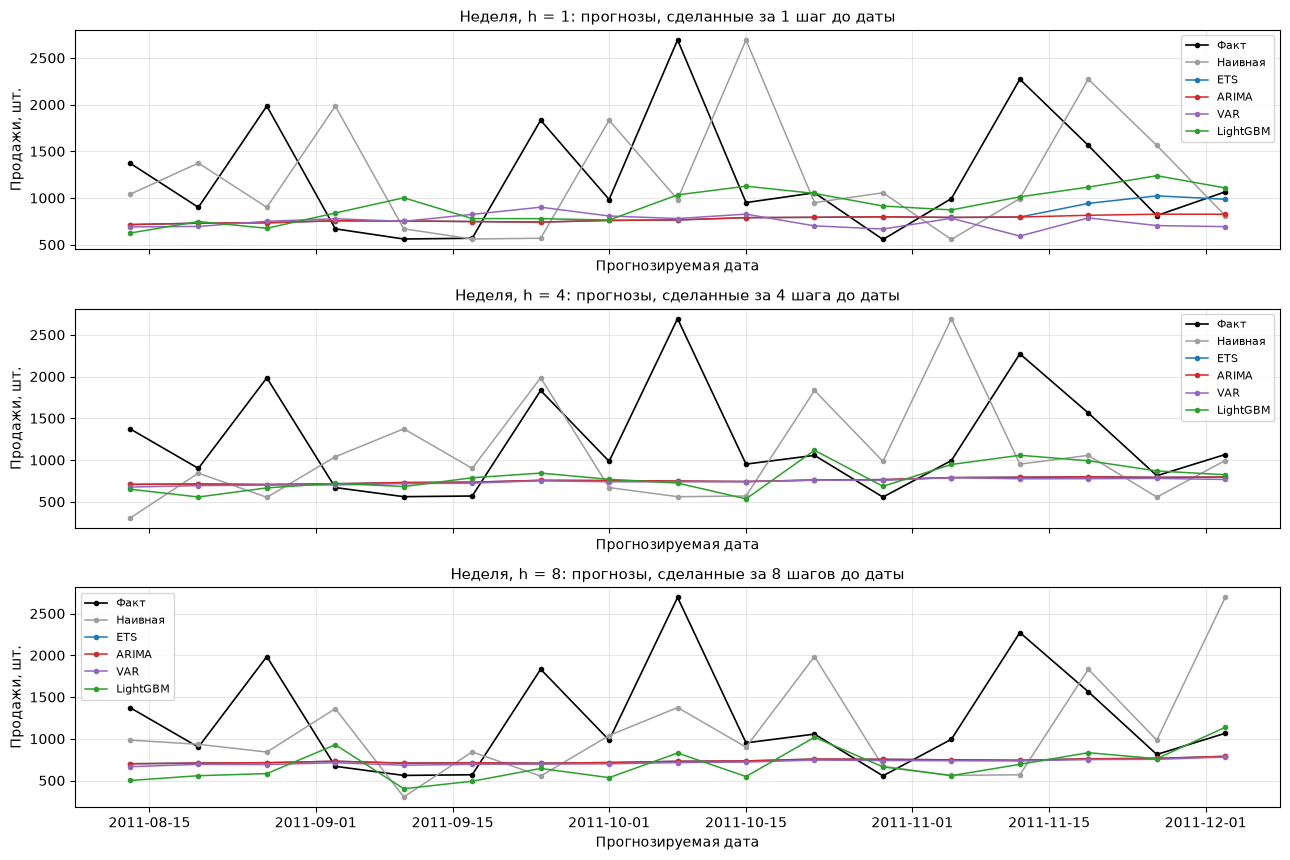

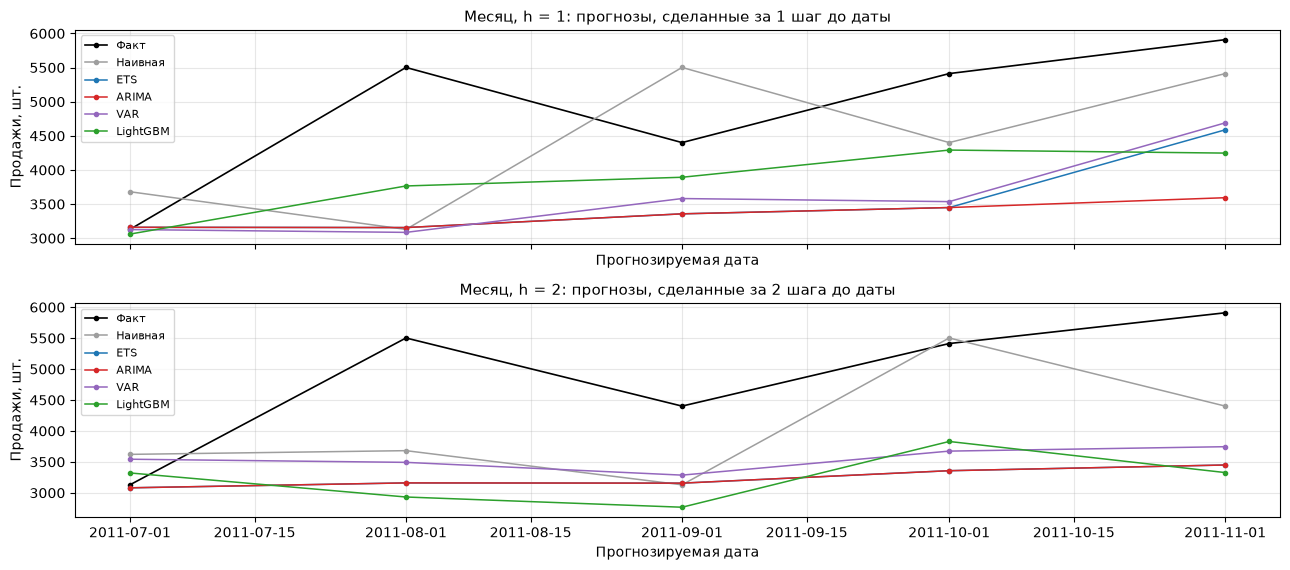

In [18]:
for f in ("Неделя", "Месяц"):
    fig = tf.plot_h_step(bt, sets[f])
    plt.show()

### Качество по горизонтам

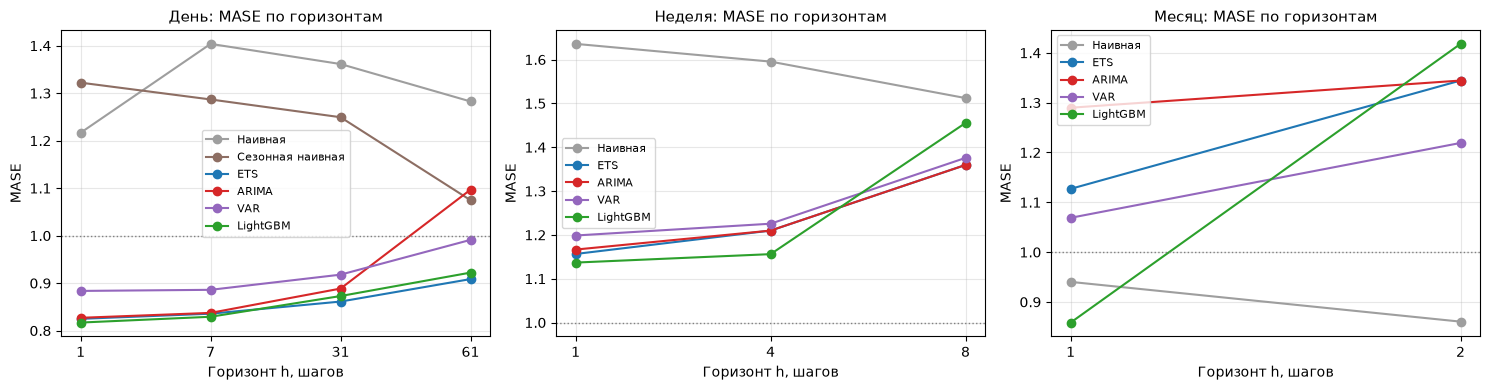

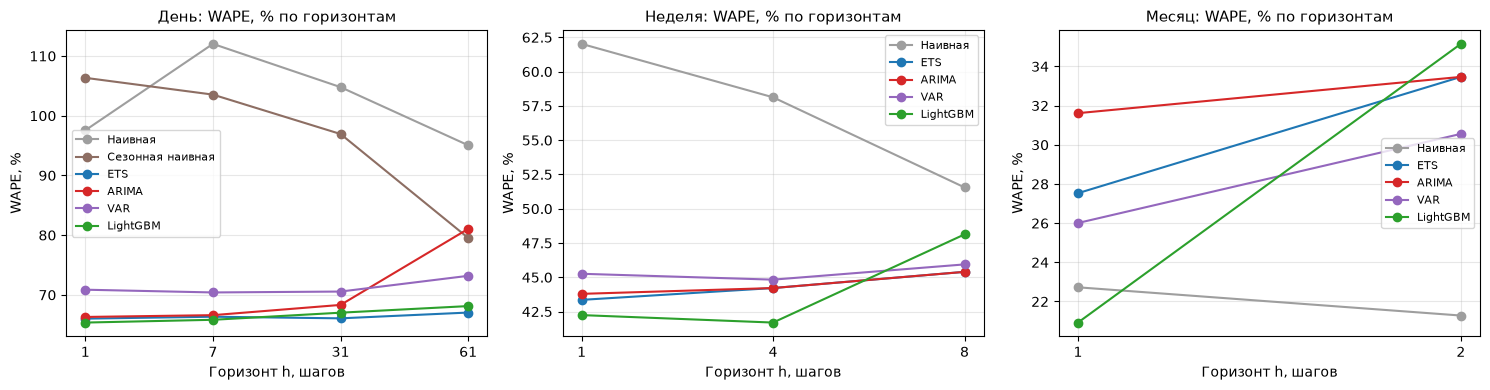

In [19]:
fig = tf.plot_metric_by_horizon(table, "MASE")
plt.show()
fig = tf.plot_metric_by_horizon(table, "WAPE, %")
plt.show()

### Все модели на одном графике

WAPE не зависит от масштаба, поэтому клетки можно сравнивать и между частотами.

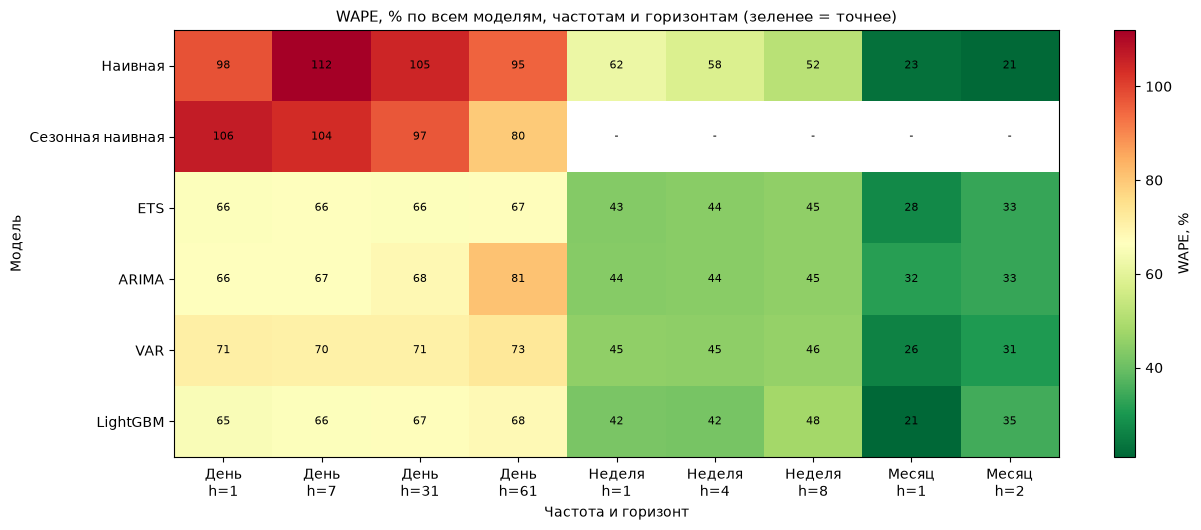

In [20]:
fig = tf.plot_heatmap(table, "WAPE, %")
plt.show()

### Важность признаков LightGBM

Модели обучены на всех данных до последней точки, показаны горизонты 1 и 61.

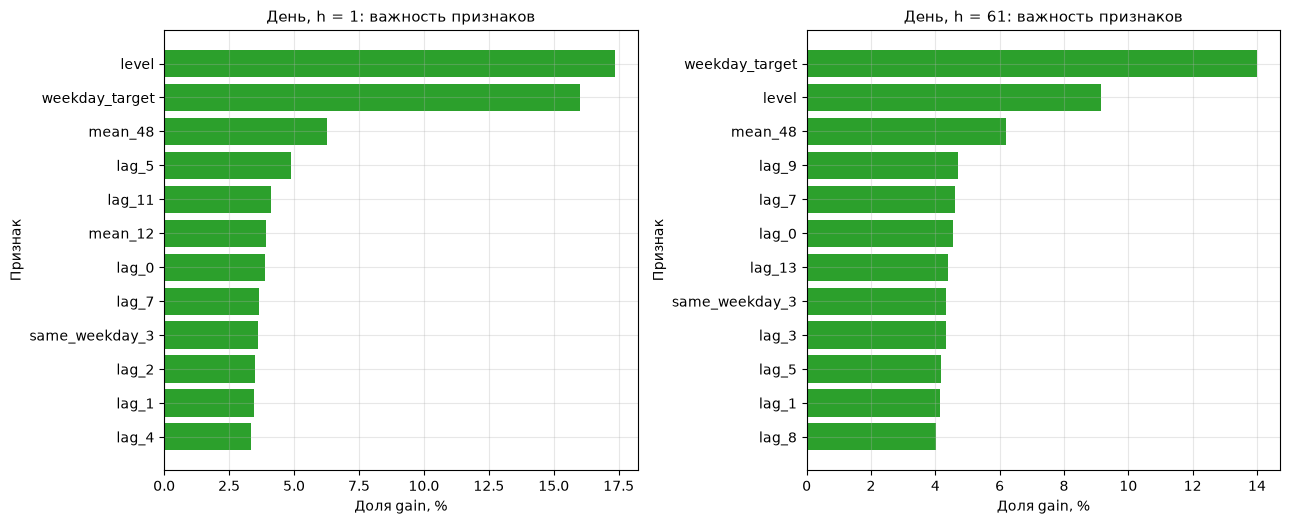

In [21]:
s = sets["День"]
fig = tf.plot_importance(M["День"]["LightGBM"], s, s.n - 1)
plt.show()

На h = 1 важнее всего текущий уровень и день недели, на h = 61 на первое место выходит день недели. Отдельные лаги дают по 3-5% на обоих горизонтах, то есть свежие значения ряда мало что добавляют.

## Шаг 6. Выводы

In [22]:
cmp = tf.comparison_table(bt, table)
print(cmp[["лучшая модель", "MASE", "WAPE, %", "MAE лучшей / MAE наивной", "вторая модель"]].round(3).to_string())

           лучшая модель  MASE  WAPE, %  MAE лучшей / MAE наивной вторая модель
частота h                                                                      
День    1       LightGBM 0.817   65.362                     0.670           ETS
        7       LightGBM 0.829   65.826                     0.588           ETS
        31           ETS 0.861   66.070                     0.631      LightGBM
        61           ETS 0.909   67.038                     0.705      LightGBM
Неделя  1       LightGBM 1.137   42.245                     0.681           ETS
        4       LightGBM 1.156   41.701                     0.717         ARIMA
        8          ARIMA 1.360   45.399                     0.881           ETS
Месяц   1       LightGBM 0.859   20.924                     0.921       Наивная
        2        Наивная 0.860   21.283                     1.000           VAR


Чтобы понять, почему VAR не помог, посмотрим, есть ли связь целевого ряда с прошлыми значениями второго ряда. Корреляции в логарифмах по начальной обучающей части:

In [23]:
pd.concat({f: tf.cross_correlation(sets[f]) for f in ("День", "Неделя")}, axis=1).round(3)

День                            Неделя              
      с другими JUMBO BAG с самим собой с другими JUMBO BAG с самим собой
лаг k                                                                    
0                   0.593         1.000               0.675         1.000
1                  -0.075         0.054               0.251         0.002
2                  -0.116        -0.022               0.152        -0.081
3                  -0.107        -0.007              -0.092        -0.149

### Лучшие модели

День. На h = 1 и 7 лучше всех LightGBM (MASE 0,82-0,83, WAPE около 66%), на h = 31 и 61 лучше ETS(A,N,A) (MASE 0,86-0,91). Вторая модель отстаёт не больше чем на 1,6% по MAE, и тест Диболда-Мариано разницы не находит (p = 0,6 и 0,8 на h = 1 и 7). То есть LightGBM, ETS и ARIMA на дневном ряду примерно одинаковы. Все три точнее наивного прогноза на 30-41% по MAE, и это значимо (p не больше 0,005).

Неделя. На h = 1 и 4 лучше LightGBM (WAPE около 42%), на h = 8 лучше ARIMA и совпадающая с ней ETS (45%). Между собой модели отличаются не больше чем на 6% по MAE (p > 0,5). Наивную модель они обгоняют на 32% и 28% по MAE на h = 1 и 4, но на 17 неделях это не значимо на уровне 5% (p = 0,06 и 0,14).

Месяц. На h = 1 лучше LightGBM (WAPE 21%), на h = 2 лучше наивная (21%). По пяти месяцам модель не выбрать: на h = 1 LightGBM точнее наивной на 8% по MAE, но p = 0,81. На месячном ряду из 12 точек ни одна модель надёжно не лучше наивного прогноза.

### Как качество зависит от горизонта

На дневном ряду ошибка лучших моделей почти не растёт. От h = 1 до h = 61 MAE у ETS меняется со 126 до 128 шт. (+1,5%), у LightGBM со 125 до 130 (+4%). Предсказать можно уровень и недельный профиль, а они меняются медленно. Основная ошибка - оптовые заказы, их не предсказать ни на каком горизонте, поэтому свежие данные мало что добавляют. С этим согласуется и то, что у ETS α около 0,03, то есть уровень почти не обновляется.

Исключение - ARIMA с линейным трендом. На h = 61 её WAPE растёт с 66 до 81%, а смещение становится положительным (+10%): тренд, оценённый по весне, продолжается на 10 недель вперёд. Для дальних горизонтов линейный тренд опасен.

На неделях ошибка растёт сильнее: MASE лучшей модели 1,14, 1,16 и 1,36 на h = 1, 4 и 8. ETS и ARIMA с α около 0 прогнозируют среднее за историю и не успевают за осенним ростом. Чем старше данные, тем сильнее занижение.

На месяцах ошибка всех моделей, кроме наивной, растёт от h = 1 к h = 2 (WAPE с 21-32% до 31-35%), но на пяти точках это нельзя отличить от случайности.

### Сравнение частот

Чем крупнее агрегация, тем меньше относительная ошибка: WAPE лучших моделей около 66% для дня, 42-45% для недели и около 21% для месяца. В недельных и месячных суммах случайные пики отдельных дней частично компенсируют друг друга. На примерно одинаковом горизонте в месяц (день h = 31, неделя h = 4, месяц h = 1) получается 66%, 42% и 21%.

Обратная сторона - меньше точек. На месячном ряду можно выбрать только самые простые модели, качество оценивается по 5 значениям, а бустинг получилось обучить только на панели товаров.

MASE между частотами напрямую сравнивать нельзя: знаменатель у каждого ряда свой, это ошибка наивного прогноза на его истории. На неделях MASE больше 1 у всех моделей, потому что осень волатильнее зимы и весны, по которым считается знаменатель. Наивный прогноз там ещё хуже (MASE 1,5-1,6).

### Ограничения и причины ошибок

1. Оптовые заказы. По ДЗ 1 треть объёма дают крупные заказы 20 клиентов, и по истории продаж их не предсказать. Поэтому WAPE дневного прогноза не опускается ниже 65%, а RMSE в 1,8-1,9 раза больше MAE.
2. Медиана вместо среднего. Модели на log(1 + x) прогнозируют медиану. Для MAE и WAPE это хорошо, но объём занижается (у ETS и LightGBM на дневном ряду на 37-55%). Если нужен суммарный объём, например для закупок, нужно прогнозировать среднее (поправка при обратном преобразовании или модель без логарифма) или нужный квантиль.
3. Нет годовой сезонности. Данные только за год, и рост перед Рождеством модели впервые видят на тесте. Отсюда занижение на дальних горизонтах. Помогли бы данные за несколько лет.
4. Короткие недельный и месячный ряды. 24 и 6 точек начального обучения мало, разница между моделями на неделях и месяцах не значима.
5. VAR не помог. С другими сумками JUMBO BAG ряд связан в основном в тот же день (корреляция 0,59), а со сдвигом на день связи почти нет (-0,08): эти сумки покупают в одних и тех же заказах. Для прогноза нужна связь с опережением, поэтому VAR получает лишние параметры без новой информации и на дне и неделе уступает ETS.
6. Праздничные недели. В неделях с банковскими выходными на 1-2 рабочих дня меньше. Число рабочих дней известно заранее, его можно добавить в модели как признак.

### Итог

Для дневного прогноза подходят ETS(A,N,A) и LightGBM. Точность у них одинаковая, но ETS проще, и ей не нужна панель товаров. Для недель - LightGBM на коротких горизонтах или простое экспоненциальное сглаживание. Для месяцев данных мало, и наивный прогноз не хуже моделей.